# Week 5 notebook: Regression Discontinuity and Instrumental Variables

Same story as today's slides: a **cutoff school** (tutoring assigned below a placement
score of 60 &rarr; RD) and a **lottery school** (tutoring offered to a random half of
applicants &rarr; IV). Everything is simulated, so we know the true effect of
**attending** tutoring on the final score: **5 points**. The point of the notebook is
to watch naive comparisons get it wrong, and the RD / IV fixes get it right &mdash; and
to reproduce every number from today's polls.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm

np.random.seed(0)

## Part 1: the cutoff school (RD)

Every student has a `placement_score`. Students below 60 are **assigned** tutoring.
Assignment isn't the same as attending: some assigned students skip it, and some
non-assigned students find tutoring elsewhere (just like the deck's "assigned &ne;
attended"). Scores depend on placement (a smooth trend, intentionally a bit curved so
Part 1's poll makes sense), on attending (true effect = 5), and on `motivation`, an
unobserved trait that makes some students both more likely to attend *and* score
higher even without tutoring.

In [2]:
def make_cutoff_school(n=3750, seed=2, true_effect=5, curve_strength=0.0013):
    rng = np.random.default_rng(seed)
    placement = rng.uniform(20, 100, n)
    r = placement - 60                      # distance from the cutoff
    assigned = (placement < 60).astype(int)

    # Latent "type": decides who attends regardless of assignment (always-takers),
    # who attends only if assigned (compliers), and who never attends.
    u = rng.uniform(0, 1, n)
    always_taker = u < 0.10
    complier = (u >= 0.10) & (u < 0.70)
    attend = np.where(always_taker, 1, np.where(complier, assigned, 0))

    # Motivation: unobserved, correlated with type (and so with attendance),
    # and it also raises scores on its own -- the confounder.
    motivation = (0.5 - u) * 3.4 + rng.normal(0, 1, n) * 0.8

    # A deliberately curved (not straight-line) trend in placement score, so a
    # regression using ALL students fits the cutoff region badly (today's poll 1/2).
    curve = curve_strength * np.sign(r) * np.abs(r) ** 2.5

    noise = rng.normal(0, 4, n)
    score = 50 + curve + true_effect * attend + 3 * motivation + noise

    return pd.DataFrame({"placement": placement, "r": r, "assigned": assigned,
                          "attend": attend, "motivation": motivation, "score": score})

cutoff_school = make_cutoff_school()
cutoff_school.head()

,placement,r,assigned,attend,motivation,score
0,40.928971,-19.071029,1,0,-3.167190,39.728955
1,43.879291,-16.120709,1,0,-0.884305,49.421645
2,85.138059,25.138059,0,1,1.314399,58.231718
3,27.353275,-32.646725,1,1,-0.212075,46.699460
4,68.008042,8.008042,0,1,1.134180,58.830698


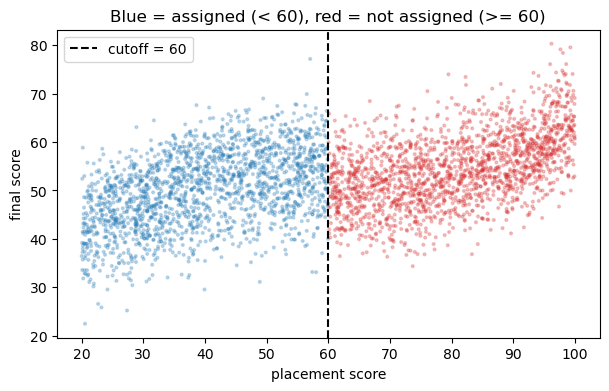

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(cutoff_school.placement, cutoff_school.score, s=4, alpha=0.25,
            c=np.where(cutoff_school.assigned, "tab:blue", "tab:red"))
plt.axvline(60, color="black", linestyle="--", label="cutoff = 60")
plt.xlabel("placement score")
plt.ylabel("final score")
plt.title("Blue = assigned (< 60), red = not assigned (>= 60)")
plt.legend()
plt.show()

# Is the jump obvious? Can a simple method work?
If it is, try removing the dotted line and color difference from the plot above.
Before reaching for a regression, try the
simplest thing that could possibly work: just average the scores of students just
below 60 and just above 60.

In [4]:
bw = 10
below = cutoff_school[(cutoff_school.placement > 60 - bw) & (cutoff_school.placement < 60)]
above = cutoff_school[(cutoff_school.placement >= 60) & (cutoff_school.placement < 60 + bw)]
below.score.mean() - above.score.mean()

2.954381302058671

# Why the simple approach fails
That number (&approx; 3) actually looks plausible -- but it's the right
answer for the wrong reason, and it doesn't survive a wider window. Try the same
two-line comparison with `bw = 40` instead of `10`: the naive difference swings to
roughly **-4**, the wrong sign entirely. Nothing about the *method* changed, only the
window -- because a plain mean difference bakes in whatever slope the score has
within that window on each side. Near the cutoff the curve is close to flat, so bw=10
is forgiving; far out it very much isn't. We need a method that explicitly fits (and
removes) that slope before reading off the jump. That's a regression with a slope
term on each side of the cutoff.

In [5]:
def rd_estimate(df, bandwidth, col="assigned"):
    sub = df[np.abs(df.r) <= bandwidth].copy()
    sub["interaction"] = sub["r"] * sub[col]

    X = sm.add_constant(sub[["r", col, "interaction"]])
    y = sub["score"]
    model = sm.OLS(y, X).fit()

    ci = model.conf_int().loc[col]
    return pd.Series({"bandwidth": bandwidth, "n": len(sub),
                       "jump (tau_hat)": model.params[col],
                       "se": model.bse[col],
                       "ci_low": ci[0], "ci_high": ci[1]})

analyst_a = rd_estimate(cutoff_school, bandwidth=40)   # the full dataset (placement in [20, 100])
analyst_b = rd_estimate(cutoff_school, bandwidth=10)
pd.DataFrame([analyst_a, analyst_b], index=["Analyst A (all)", "Analyst B (+-10)"])

,bandwidth,n,jump (tau_hat),se,ci_low,ci_high
Analyst A (all),40.0,3750.0,8.015094,0.434848,7.162532,8.867656
Analyst B (+-10),10.0,902.0,3.516430,0.863252,1.822204,5.210656


**Answer to Poll 1 (C):** both analysts fit a *straight* line to each side
(the `r` and `interaction` terms). Across the whole range the true trend bends, so
Analyst A's lines are pulled by students far from 60 and miss badly right at the
cutoff. Analyst B only trusts the local straight-line approximation, which is much
safer near 60.

Now Poll 2: push the window even narrower. Try it yourself &mdash; change
`bandwidths` below.

In [6]:
bandwidths = [40, 10, 3]   # <- try adding e.g. 1 or 20
table = pd.DataFrame([rd_estimate(cutoff_school, bw) for bw in bandwidths])
table

,bandwidth,n,jump (tau_hat),se,ci_low,ci_high
0,40.0,3750.0,8.015094,0.434848,7.162532,8.867656
1,10.0,902.0,3.516430,0.863252,1.822204,5.210656
2,3.0,275.0,2.645955,1.699627,-0.700197,5.992107


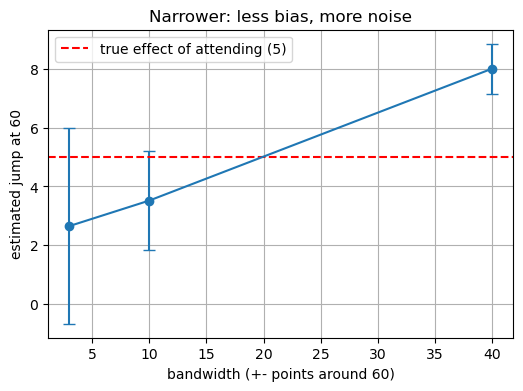

In [7]:
plt.figure(figsize=(6, 4))
plt.errorbar(table.bandwidth, table["jump (tau_hat)"],
             yerr=1.96 * table.se, fmt="o-", capsize=4)
plt.axhline(5, color="red", linestyle="--", label="true effect of attending (5)")
plt.xlabel("bandwidth (+- points around 60)")
plt.ylabel("estimated jump at 60")
plt.title("Narrower: less bias, more noise")
plt.legend()
plt.grid(True)
plt.show()

**Answer to Poll 2 (B):** the +-3 window has the *least* bias but a confidence
interval wide enough to contain both 0 and the +-10 estimate &mdash; "not significant"
is not the same as "no effect." The +-40 (or wider) row is precise but is fitting the
wrong shape, so it's precisely wrong.

## Wait -- shouldn't this be 5, not ~3?

Analyst B's window gives a jump around 3, not the true effect of 5 we built in.
Tempting fix: the regression above uses `assigned`, but what we actually care about
is *attending*. Let's just swap the column.

In [8]:
rd_estimate(cutoff_school, bandwidth=10, col="attend")

bandwidth          10.000000
n                 902.000000
jump (tau_hat)      8.892543
se                  0.439789
ci_low              8.029409
ci_high             9.755677
dtype: float64

That's *worse*, not better &mdash; the jump using `attend` overshoots 5 by a
lot. `assigned` is (locally, near the cutoff) as good as random: which side of 60 a
student lands on has nothing to do with their motivation. `attend` is not: whether a
student actually shows up is exactly the thing motivation drives. Swapping the column
traded a small, honest bias (not everyone complies) for a large, dishonest one
(self-selection). `assigned` was the right choice all along.

So if `assigned` is unconfounded, why isn't its jump exactly 5? Because not
everyone's attendance *changes* at the cutoff. Only compliers switch; always-takers
attend either way and never-takers skip either way, so their scores don't jump at 60
at all. The jump we measure is the true effect diluted by the fraction of students
whose behavior the cutoff actually moves.

In [9]:
# true effect of ATTENDING (5) x share of students whose attendance the cutoff
# actually changes (the compliers, 60% of students: 0.70 - 0.10)
true_effect = 5
complier_share = 0.70 - 0.10
true_effect * complier_share

3.0

That `0.6` is exactly `P(complier)`: just below 60 (assigned), attend = 1 for
always-takers and compliers, so `P(attend | assigned) = 0.70`; just above 60 (not
assigned), attend = 1 only for always-takers, so `P(attend | not assigned) = 0.10`.
The jump in attendance at the cutoff is `0.70 - 0.10 = 0.60`, which is just another
way of writing "the fraction of students who are compliers." Analyst B's ~3.5 is
noisy-but-right: it's estimating `5 * 0.6 = 3`, the effect of *assignment*, not the
effect of *attending*. Getting the effect of attending itself is exactly the job of
Part 3's fuzzy RD, below.

## Part 2: the lottery school (IV)

Different school, same underlying idea: `motivation` affects both attendance and
score, but now there's no cutoff to exploit. Instead, limited places mean a **lottery**
randomly **offers** tutoring to half the applicants. The offer nudges attendance but
doesn't determine it: some offered students skip it, some non-offered students attend
elsewhere (again, 10% / 50% / 40%, exactly like the deck).

In [10]:
def make_lottery_school(n=8000, seed=1, true_effect=5, motivation_strength=3.4):
    rng = np.random.default_rng(seed)
    offer = rng.binomial(1, 0.5, n)

    u = rng.uniform(0, 1, n)
    always_taker = u < 0.10
    complier = (u >= 0.10) & (u < 0.50)
    attend = np.where(always_taker, 1, np.where(complier, offer, 0))

    motivation = (0.5 - u) * motivation_strength + rng.normal(0, 1, n) * 0.8
    noise = rng.normal(0, 4, n)
    score = 50 + true_effect * attend + 3 * motivation + noise

    return pd.DataFrame({"offer": offer, "attend": attend,
                          "motivation": motivation, "score": score})

lottery_school = make_lottery_school()
lottery_school.head()

,offer,attend,motivation,score
0,1,0,-0.899093,43.146507
1,1,1,0.613581,63.394942
2,0,0,-1.136566,41.856699
3,1,1,-0.683424,56.672817
4,0,0,-1.348326,46.372558


In [11]:
naive = smf.ols("score ~ attend", data=lottery_school).fit()
naive.params["attend"]

8.932790264600017

That's the naive, **confounded** comparison (matches "Attended vs not" in
today's final table, &approx; 9). Motivated students attend *and* score higher on
their own &mdash; the regression can't tell the two apart.

Now the lottery: `offer` is random, so it can't be confounded with motivation. The
**Wald estimator** divides the offer's effect on scores by the offer's effect on
attendance:

$$
\hat\beta_{\text{Wald}} \;=\; \frac{E[\text{score} \mid \text{offer}=1] - E[\text{score} \mid \text{offer}=0]}
{E[\text{attend} \mid \text{offer}=1] - E[\text{attend} \mid \text{offer}=0]}
\;=\; \frac{\text{ITT on score}}{\text{ITT on attend}}
$$

Both the numerator and the denominator only ever compare offered vs. not-offered --
and the offer is random, so neither piece is confounded by motivation.

In [12]:
itt_score = (lottery_school.loc[lottery_school.offer == 1, "score"].mean()
             - lottery_school.loc[lottery_school.offer == 0, "score"].mean())
itt_attend = (lottery_school.loc[lottery_school.offer == 1, "attend"].mean()
              - lottery_school.loc[lottery_school.offer == 0, "attend"].mean())

print("ITT on score (numerator):     ", round(itt_score, 2))
print("ITT on attend (denominator):  ", round(itt_attend, 2))
print("Wald estimate:                ", round(itt_score / itt_attend, 2))

ITT on score (numerator):      1.99
ITT on attend (denominator):   0.41
Wald estimate:                 4.89


That recovers something very close to the true **5** &mdash; the average gain
for the students whose attendance the offer actually changed (the compliers).

**Poll 3's trap:** a colleague suggests *controlling* for the offer in the regression
of score on attendance, since the offer is "just random." Try it:

In [13]:
controlled = smf.ols("score ~ attend + offer", data=lottery_school).fit()
print("naive b (no control):        ", round(naive.params["attend"], 2))
print("b controlling for offer:      ", round(controlled.params["attend"], 2))

naive b (no control):         8.93
b controlling for offer:       9.91


**Answer to Poll 3 (C):** controlling for the offer makes it *worse*, not
better. Within the offered group, attenders are the most motivated 50%, non-attenders
the least motivated 50%; within the non-offered group, attenders are only the most
motivated 10%. Conditioning on the instrument *keeps* that motivation-driven variation
in attendance and throws away the clean, offer-driven variation &mdash; the opposite of
what we want (this is "bias amplification," not a simulation quirk).

**Try it:** raise `motivation_strength` in `make_lottery_school(...)` (e.g. to 6) and
rerun both regressions above. The naive and controlled estimates should both get
worse, while the Wald estimate barely moves &mdash; it never uses motivation at all.

## Part 3: fuzzy RD &mdash; back to the cutoff school

The lottery isn't available everywhere. But near the cutoff, landing just above or
just below 60 is close to random: that's our "lottery" at the cutoff school. We
already have the pieces &mdash; the jump in **attendance** at 60, and the jump in
**score** at 60, within the same local window. This directly answers the question
Part 1 left open: the effect of *attending*, not just of being *assigned*.

In [14]:
window = cutoff_school[np.abs(cutoff_school.r) <= 10]
attend_above = window.loc[window.assigned == 0, "attend"].mean()
attend_below = window.loc[window.assigned == 1, "attend"].mean()
attend_jump = attend_below - attend_above

score_jump = rd_estimate(cutoff_school, bandwidth=10)["jump (tau_hat)"]

print("attend rate | assigned:    ", round(attend_below, 2))
print("attend rate | not assigned:", round(attend_above, 2))
print("attendance jump at 60:     ", round(attend_jump, 2))
print("score jump at 60 (tau):    ", round(score_jump, 2))
print("fuzzy RD estimate = score jump / attend jump:", round(score_jump / attend_jump, 2))

attend rate | assigned:     0.69
attend rate | not assigned: 0.09
attendance jump at 60:      0.6
score jump at 60 (tau):     3.52
fuzzy RD estimate = score jump / attend jump: 5.86


**Answer to Poll 4 (C):** divide by the jump in *attendance* (assigned minus
not-assigned), not by 0.7 alone &mdash; some students above 60 attend anyway, so only
the jump is the "as-good-as-random" part. Notice the denominator here, `0.6`, is the
exact same complier share from the discount-factor calculation in Part 1.

This fuzzy-RD estimate and the lottery's IV estimate are two *different* local
answers (different students, different instrument), so they needn't match exactly in
a single simulated draw &mdash; both are estimating something close to the true 5.

## Putting it together

Reproducing today's closing table, with numbers computed above instead of asserted.

In [15]:
summary = pd.DataFrame({
    "comparison": ["Attended vs not (naive)",
                   "Just below vs above 60 (assignment, Analyst B)",
                   "Offered vs not (lottery ITT)",
                   "Offer / attendance jump (lottery IV, Wald)",
                   "Cutoff / attendance jump (fuzzy RD)"],
    "estimate": [naive.params["attend"],
                 analyst_b["jump (tau_hat)"],
                 itt_score,
                 itt_score / itt_attend,
                 score_jump / attend_jump],
    "confounded?": ["Yes: motivation", "No, at 60", "No: random", "No", "No, at 60"],
}).round(2)
summary

,comparison,estimate,confounded?
0,Attended vs not (naive),8.93,Yes: motivation
1,"Just below vs above 60 (assignment, Analyst B)",3.52,"No, at 60"
2,Offered vs not (lottery ITT),1.99,No: random
3,"Offer / attendance jump (lottery IV, Wald)",4.89,No
4,Cutoff / attendance jump (fuzzy RD),5.86,"No, at 60"


## Try it yourself

All the knobs are exposed as function arguments above:

- `make_cutoff_school(curve_strength=...)` &mdash; set to 0 to remove the global-fit
  bias; the Analyst A / B gap in Part 1 should vanish.
- `make_lottery_school(motivation_strength=...)` &mdash; raise it to make the naive
  and offer-controlled estimates worse while the Wald estimate stays near 5.
- Either function's `true_effect=...` &mdash; change it and re-run everything; every
  estimate in the summary table except "naive" and the controlled regression should
  track it.
- `n=...` in either function &mdash; shrink it to see the confidence intervals widen,
  just like narrowing the RD bandwidth did in Poll 2.

**Extra exercise: does narrowing the window always protect you from confounding?**

So far `placement` has been independent of `motivation` &mdash; narrowing the window
in Part 1 only ever bought you a better local line, never protection from a
confounder, because there was never one on `placement` to begin with. Walk through
this in three steps:

1. Set `curve_strength=0` and rerun the bandwidth table. Analyst A and Analyst B
   should now agree (both close to 3, the assignment-effect target) &mdash; confirming
   there's no confounding baked in at any window width.
2. Now make `placement` depend on `motivation`, e.g. inside `make_cutoff_school`:
   `placement = 60 + 10 * motivation + rng.uniform(-30, 30, n)`. This creates exactly
   the thing Poll 1 warned about: a confounder (motivation) that also drives who
   lands on which side of the cutoff.
3. Compare a narrow window (`bandwidth=10`) to a wide one (`bandwidth=40`). The narrow
   window should now come out closer to the assignment-effect target than the wide
   one &mdash; this is the textbook case for "narrow windows protect you from
   confounding."

**A noise warning for step 3:** at this sample size, a *single* random draw can look
reversed about 1 in 5 times purely from sampling noise &mdash; we hit this ourselves
while preparing this notebook. If your run looks backwards, don't conclude the logic
is wrong before trying one of: (a) compare `bandwidth=10` vs. `bandwidth=40` rather
than an extremely tight window like `bandwidth=3` (which is the noisiest row in the
table), or (b) raise `n` in `make_cutoff_school(...)` substantially (several times
larger) and rerun -- the expected direction should show up consistently.